In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt

In [13]:
# 1. 读取图片数据
img = plt.imread('../data/duck.jpg')
print(img.shape)

(1080, 1080, 3)


In [14]:
# 2. 转换为张量，并调整形状
input = torch.tensor(img).permute(2, 0, 1).float()
print(input.shape)

torch.Size([3, 1080, 1080])


In [16]:
# 3. 定义卷积层
conv = nn.Conv2d(3, 3, kernel_size=9, stride=3, padding=0, bias=True)
# 4. 卷积
output = conv(input)
print(output.shape)

torch.Size([3, 358, 358])


In [17]:
# 5. 定义池化层
pool = nn.MaxPool2d(kernel_size=6, stride=6, padding=0)
output_pool = pool(output)
print(output_pool.shape)

torch.Size([3, 59, 59])


In [6]:
output = torch.clamp(output.int(), 0, 255)
output = output.permute(1, 2, 0).detach()
output_pool = torch.clamp(output_pool.int(), 0, 255)
output_pool = output_pool.permute(1, 2, 0).detach()

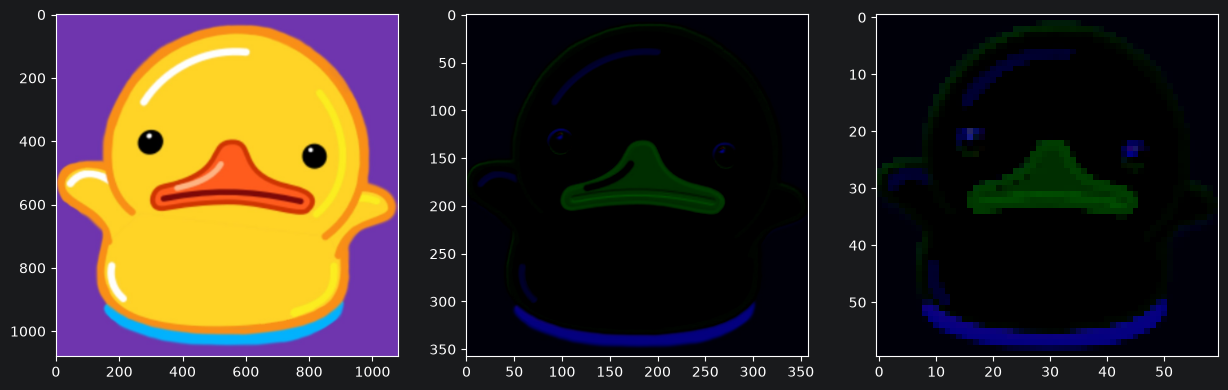

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img)
ax[1].imshow(output)
ax[2].imshow(output_pool)
plt.show()

# 总结
- 减少过拟合 因为变小了 图变简单了 只取最大最亮的点(Max 池化较多) 马赛克
- 一般S=K保证没有重叠
- 池化后只变小 通道数不变，不需要输入通道参数